Carregamento de dados e importação de bibliotecas

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

data = pd.read_csv("rent.csv")

X = data.drop('price', axis=1).drop('interest_level', axis=1).values
y = data['price'].values

scaler = StandardScaler()
X = scaler.fit_transform(X)


Exercício 5

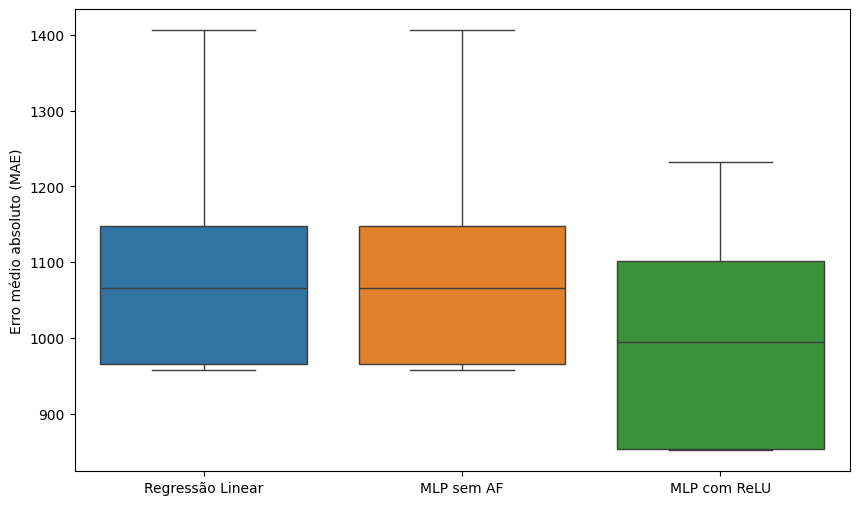

In [7]:
np.random.seed(0)
kf = KFold(n_splits=5)

mae_lr = []
mae_mlp_naf = []
mae_mlp_ReLu = []

lr_model = LinearRegression()
mlp_naf = MLPRegressor(hidden_layer_sizes=(5,5), activation='identity', max_iter=1000, solver='lbfgs', random_state=0)
mlp_ReLu = MLPRegressor(hidden_layer_sizes=(5,5), activation='relu', max_iter=1000, solver='lbfgs', random_state=0)

for train_i, test_i in kf.split(X):
    X_train, X_test = X[train_i], X[test_i]
    y_train, y_test = y[train_i], y[test_i]

    lr_model.fit(X_train, y_train)
    y_pred_lr = lr_model.predict(X_test)
    mae_lr.append(mean_absolute_error(y_test,y_pred_lr))

    mlp_naf.fit(X_train, y_train)
    y_pred_mlp_naf = mlp_naf.predict(X_test)
    mae_mlp_naf.append(mean_absolute_error(y_test, y_pred_mlp_naf))
    
    mlp_ReLu.fit(X_train, y_train)
    y_pred_mlp_ReLu = mlp_ReLu.predict(X_test)
    mae_mlp_ReLu.append(mean_absolute_error(y_test,y_pred_mlp_ReLu))

plt.figure(figsize=(10,6))
sns.boxplot(data=[mae_lr, mae_mlp_naf, mae_mlp_ReLu])
plt.xticks([0, 1, 2], ['Regressão Linear', 'MLP sem AF', 'MLP com ReLU'])
plt.ylabel('Erro médio absoluto (MAE)')
plt.show()

Exercício 7


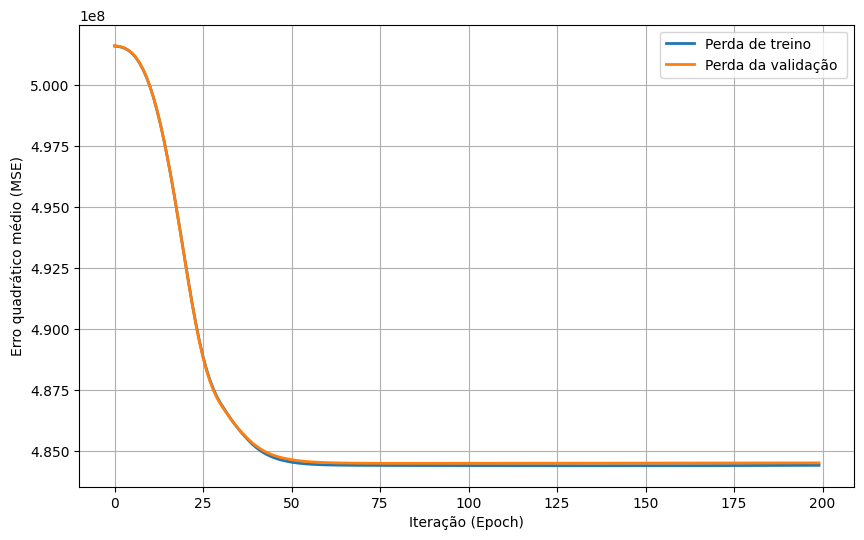

In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)

# Listas para guardar as curvas de loss de cada fold
loss_train = []
loss_val = []

n_epochs = 200  # número de iterações (epochs) que vamos treinar cada fold

# Loop pelos folds do K-Fold
for train_i, val_i in kf.split(X):
    # Separar os dados de treino e validação do fold atual
    X_train, X_val = X[train_i], X[val_i]
    y_train, y_val = y[train_i], y[val_i]

    # Inicializar o modelo MLP com ReLU
    # max_iter=1 e warm_start=True permitem treinar "uma época de cada vez"
    mlp_ReLu = MLPRegressor(hidden_layer_sizes=(5,5),
                            activation='relu',
                            random_state=0,
                            max_iter=1,
                            warm_start=True)  # faz com que não se percam os pesos anteriores

    # Listas temporárias para armazenar a curva de loss do fold atual
    train_losses = []
    val_losses = []

    # Loop por cada epoch
    for epoch in range(n_epochs):
        # Treinar o modelo mais uma época com os dados de treino
        mlp_ReLu.fit(X_train, y_train)

        y_pred_train = mlp_ReLu.predict(X_train)
        train_losses.append(mean_squared_error(y_train, y_pred_train))     

        # Fazer previsão no conjunto de validação e calcular a MSE
        y_pred_val = mlp_ReLu.predict(X_val)
        val_losses.append(mean_squared_error(y_val, y_pred_val))

    # Guardar as curvas deste fold nas listas principais
    loss_train.append(train_losses)
    loss_val.append(val_losses)

# Calcular a média das curvas de loss entre todos os folds
train_mean = np.mean(loss_train, axis=0)
val_mean = np.mean(loss_val, axis=0)

# Plotar as curvas médias de training e validation loss
plt.figure(figsize=(10,6))
plt.plot(train_mean, label='Perda de treino', linewidth=2)
plt.plot(val_mean, label='Perda da validação ', linewidth=2)
plt.xlabel('Iteração (Epoch)')
plt.ylabel('Erro quadrático médio (MSE)')
plt.legend()
plt.grid(True)
plt.show()